# Safe: multi-asset dual momentum (research)

Monthly-rebalanced multi-asset strategy built for capital preservation.

1. **Eligibility**: month-end price above the 200-day SMA and positive 3-month return.
2. **Diversification filter**: among eligible assets, if two have a 6-month daily-return correlation above 0.80, the one with weaker momentum is dropped. At most 5 assets are kept.
3. **Sizing**: weights proportional to 3-month momentum, capped at 25% per asset (40% when the strongest asset is up more than 5% over 3 months). Unallocated weight goes to 0-1Y T-bills (SHV).

An inverse-volatility version of step 3 is tested as an alternative. The last section asks whether the strategy adds anything beyond a 60/40, 1/N, risk parity, naive trend-following and simple factor exposures.

The same functions (`src/strategies.py`) drive the live paper-trading notebook.

In [1]:
import os
import sys

import numpy as np
import pandas as pd

sys.path.append(os.path.join("..", "src"))
from data import download_prices, prepare_monthly
from strategies import trend_momentum_signal, correlation_filter, momentum_weights, inverse_vol_weights
from backtest import run_backtest, allocation_stats, stress_test
import benchmarks as bm

np.random.seed(42)
DATA_DIR = os.path.join("..", "data")

/opt/miniconda3/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
UNIVERSE = ["SPY", "QQQ", "IWM", "VWO", "GLD", "SHV", "IEF", "TLT", "TIP", "LQD"]
SMA_WINDOW = 200
MAX_ASSETS = 5
CORR_THRESHOLD = 0.80
BASE_CAP, TURBO_CAP, TURBO_TRIGGER = 0.25, 0.40, 0.05

# One-way trading cost per ETF (spread + commission estimate)
TICKER_COSTS = {"SPY": 0.0002, "QQQ": 0.0003, "SHV": 0.0001, "IEF": 0.0002, "TLT": 0.0003,
                "IWM": 0.0004, "GLD": 0.0004, "LQD": 0.0004, "VWO": 0.0008, "TIP": 0.0003}

## 1. Data and signal

In [3]:
prices = download_prices(UNIVERSE, years=20, cache_path=os.path.join(DATA_DIR, "prices_safe.csv"))
md = prepare_monthly(prices, SMA_WINDOW)
signal = trend_momentum_signal(md)

print(f"\n{len(md.prices)} months x {md.prices.shape[1]} ETFs. Latest eligibility:")
print(signal.tail(3).T)

Downloaded 2006-10-17 -> 2026-10-12. First valid date per ETF:
  SPY   2006-10-17
  QQQ   2006-10-17
  IWM   2006-10-17
  VWO   2006-10-17
  GLD   2006-10-17
  SHV   2007-01-11
  IEF   2006-10-17
  TLT   2006-10-17
  TIP   2006-10-17
  LQD   2006-10-17

240 months x 10 ETFs. Latest eligibility:
Date    2026-07-31  2026-08-31  2026-09-30
Ticker                                    
GLD          False       False       False
IEF          False       False       False
IWM           True        True       False
LQD          False       False       False
QQQ           True       False        True
SHV           True        True        True
SPY           True        True        True
TIP          False       False       False
TLT          False       False       False
VWO          False        True       False


## 2. Portfolio construction

In [4]:
selected = correlation_filter(signal, md.mom_3m, md.daily_returns, MAX_ASSETS, CORR_THRESHOLD)
w_momentum = momentum_weights(selected, md.mom_3m, BASE_CAP, TURBO_CAP, TURBO_TRIGGER)
w_invvol = inverse_vol_weights(selected, md.daily_returns, max_weight=BASE_CAP)

print("Latest momentum-weighted portfolio:")
print((w_momentum.iloc[-1][w_momentum.iloc[-1] > 0] * 100).round(1).to_string())

Latest momentum-weighted portfolio:
Ticker
SHV    75.0
SPY    25.0


## 3. Backtest net of costs

PERFORMANCE: Safe (momentum weights)  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      8.96%      9.35%   0.74  -14.2%
Net (per-ETF costs)   8.66%      9.34%   0.71  -14.3%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



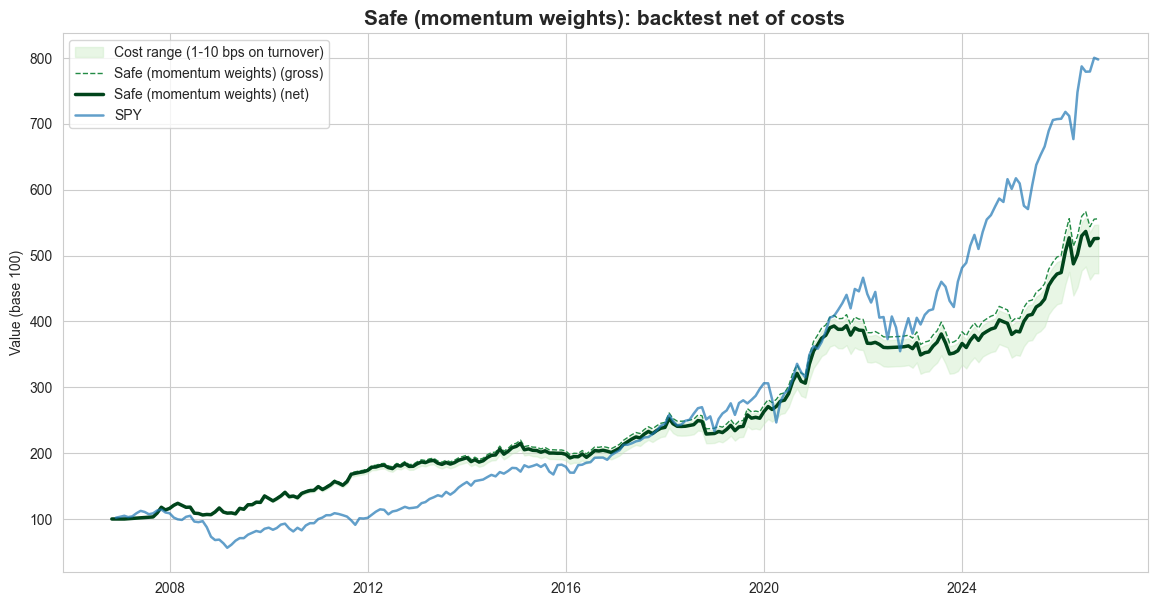

ALLOCATION HISTORY: 240 months since 2006-10-31
        Months held  Frequency %  Avg weight when held %  Max weight %
Ticker                                                                
SHV             166         69.2                    32.6         100.0
GLD             120         50.0                    28.5          40.0
VWO             112         46.7                    26.7          40.0
QQQ             110         45.8                    31.9          40.0
TIP              90         37.5                    15.4          34.6
LQD              89         37.1                    16.1          40.0
TLT              86         35.8                    27.3          40.0
IWM              79         32.9                    30.3          40.0
SPY              29         12.1                    24.4          40.0
IEF              22          9.2                    18.0          40.0 



In [5]:
bt_mom = run_backtest(w_momentum, md.returns, TICKER_COSTS, "Safe (momentum weights)")
alloc_mom = allocation_stats(w_momentum, os.path.join(DATA_DIR, "allocation_safe_momentum.csv"))

PERFORMANCE: Safe (inverse-vol weights)  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)      7.12%      6.64%   0.77   -9.8%
Net (per-ETF costs)   6.90%      6.63%   0.74   -9.9%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



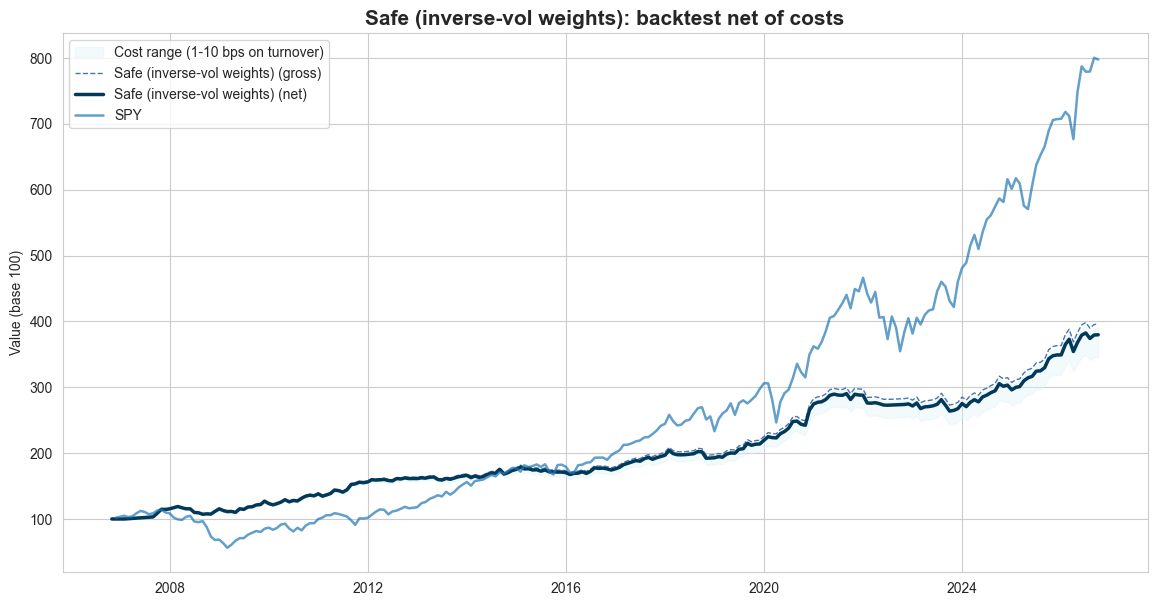

ALLOCATION HISTORY: 240 months since 2006-10-31
        Months held  Frequency %  Avg weight when held %  Max weight %
Ticker                                                                
SHV             179         74.6                    44.8         100.0
GLD             120         50.0                    20.5          25.0
VWO             112         46.7                    19.9          25.0
QQQ             110         45.8                    21.6          25.0
TIP              90         37.5                    24.1          25.0
LQD              89         37.1                    23.6          25.0
TLT              86         35.8                    22.1          25.0
IWM              79         32.9                    20.2          25.0
SPY              29         12.1                    21.3          25.0
IEF              22          9.2                    24.6          25.0 



In [6]:
bt_iv = run_backtest(w_invvol, md.returns, TICKER_COSTS, "Safe (inverse-vol weights)",
                     colors=("#4575b4", "#023858", "#e0f3f8"))
alloc_iv = allocation_stats(w_invvol, os.path.join(DATA_DIR, "allocation_safe_invvol.csv"))

## 4. Stress test

Deterministic shocks are applied to the *average* portfolio over the backtest; the bootstrap resamples its monthly returns over 12 months. Both are rough: the live portfolio can be far from the average one.

STRESS TEST: Safe (momentum weights)
Scenario                         |  Impact on average portfolio
2008 crash (deflation)           |                      -13.13%
1970s-style inflation            |                       -2.62%
Tech bubble burst                |                       -8.99%


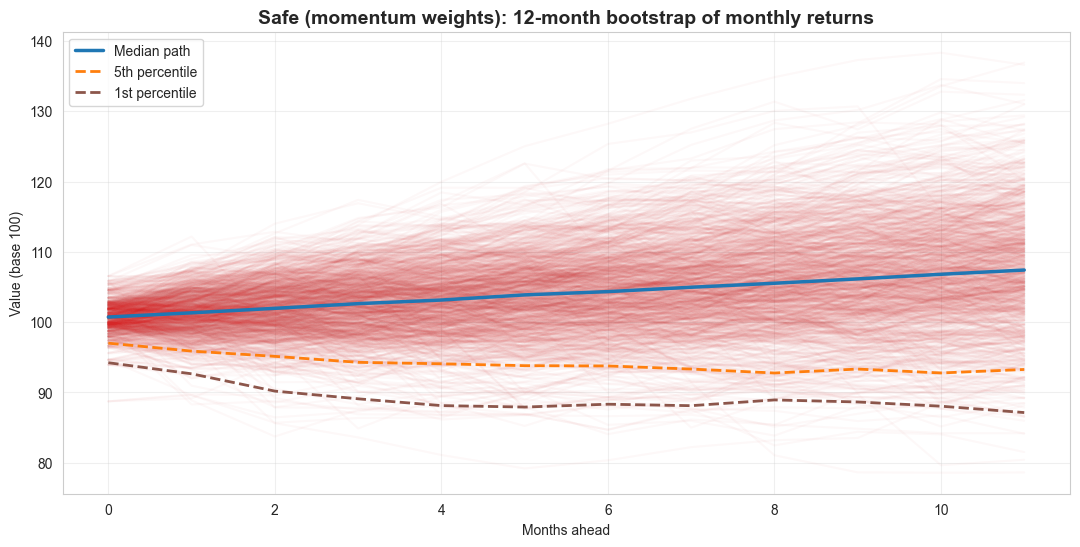

12-month VaR 95%: 6.74%   |   12-month VaR 99%: 12.87%

STRESS TEST: Safe (inverse-vol weights)
Scenario                         |  Impact on average portfolio
2008 crash (deflation)           |                       -9.52%
1970s-style inflation            |                       -1.94%
Tech bubble burst                |                       -6.61%


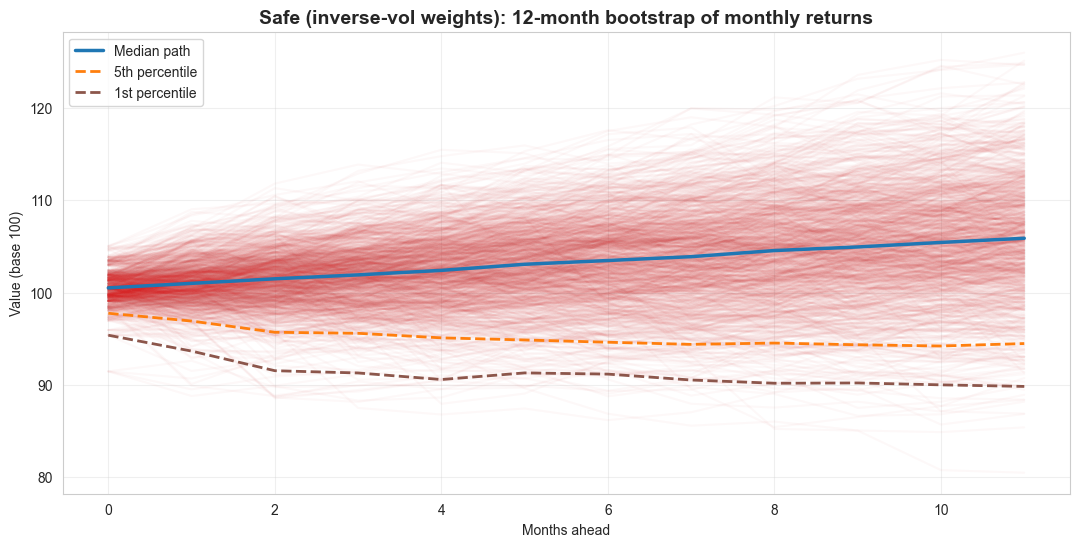

12-month VaR 95%: 5.52%   |   12-month VaR 99%: 10.16%



In [7]:
SCENARIOS = {
    "2008 crash (deflation)": {"SPY": -0.30, "QQQ": -0.35, "IWM": -0.40, "VWO": -0.45, "GLD": 0.10,
                               "TLT": 0.15, "IEF": 0.10, "SHV": 0.0},
    "1970s-style inflation":  {"SPY": -0.15, "QQQ": -0.20, "TLT": -0.25, "IEF": -0.15, "GLD": 0.30,
                               "TIP": 0.10, "SHV": 0.0},
    "Tech bubble burst":      {"QQQ": -0.50, "SPY": -0.20, "IWM": -0.15, "TLT": 0.10, "GLD": 0.05, "SHV": 0.0},
}
stress_test(w_momentum, md.returns, "Safe (momentum weights)", SCENARIOS, unmapped_shock=-0.05)
stress_test(w_invvol, md.returns, "Safe (inverse-vol weights)", SCENARIOS, unmapped_shock=-0.05);

## 5. Alpha and benchmark analysis

Beating the S&P 500 on drawdown says little for a multi-asset portfolio. The relevant questions:

- **60/40**: the standard balanced allocation with similar volatility.
- **1/N**: same universe, no signal. Measures the value of selection.
- **ERC**: same universe, equal risk contribution. The most serious systematic alternative.
- **Trend 1/N**: textbook trend-following (10-month SMA) on the same universe. Does the engine add anything over it?
- **Factor models**: static asset-class exposures, then the same plus a time-series momentum factor.

Swap `STRAT` / `WEIGHTS` for `bt_iv["net"]` / `w_invvol` to test the inverse-vol version.

In [8]:
STRAT_NAME = "Safe (net)"
STRAT, WEIGHTS, R = bt_mom["net"].copy(), w_momentum, md.returns
RISKY = [c for c in md.prices.columns if c != "SHV"]

bm.check_weights(WEIGHTS)
ff = bm.load_fama_french(os.path.join(DATA_DIR, "ff_factors_monthly.csv"))
rf = ff["RF"] if ff is not None else R["SHV"].fillna(0.0)       # 1-month T-bill

benchmarks = {
    "60/40 (SPY/IEF)":     bm.returns_from_weights(bm.fixed_mix(md.prices.index, {"SPY": 0.6, "IEF": 0.4}), R),
    "1/N universe":        bm.returns_from_weights(bm.equal_weight(md.prices, RISKY), R),
    "ERC universe":        bm.returns_from_weights(bm.erc(md.daily_returns, md.prices.index, RISKY), R),
    "Trend 1/N (10m SMA)": bm.returns_from_weights(bm.naive_trend(md.prices, RISKY), R),
    "S&P 500 (SPY)":       R["SPY"],
}
S, B, RF = bm.align_sample(STRAT, benchmarks, rf, WEIGHTS)
comparison = bm.benchmark_comparison(S, B, RF, STRAT_NAME)

Weights check: every month sums to 100%.

Fama-French: 1963-07 -> 2026-08, downloaded
Common sample: 2007-09 -> 2026-08 (228 months)

BENCHMARK COMPARISON: Safe (net)
                       CAGR     Vol Sharpe    MaxDD Calmar  Active      TE     IR  Beta  Alpha  t(α) p(ΔSR)
Safe (net)            8.95%   9.57%   0.80  -14.29%   0.63                                                 
60/40 (SPY/IEF)       8.20%   9.56%   0.73  -29.46%   0.28   0.70%   9.87%   0.07  0.47  4.39%  2.20   0.77
1/N universe          7.70%   9.52%   0.68  -23.24%   0.33   1.16%   8.71%   0.13  0.59  3.83%  2.04   0.59
ERC universe          6.12%   7.37%   0.66  -19.79%   0.31   2.84%   8.03%   0.35  0.75  4.03%  2.20   0.50
Trend 1/N (10m SMA)   6.14%   5.59%   0.85   -8.16%   0.75   2.93%   5.80%   0.50  1.43  0.88%  0.78   0.72
S&P 500 (SPY)        11.09%  15.58%   0.67  -50.78%   0.22  -2.72%  14.69%  -0.19  0.25  5.12%  2.41   0.60
Active = strategy - benchmark (ann.) | TE = tracking error | IR = Active / TE

FACTOR MODEL: Asset-class factors
                   Coefficient t-stat (NW) p-value
Alpha              +2.74% p.a.        1.43   0.154
Equity (SPY-RF)         +0.231        3.79   0.000
Duration (IEF-RF)       +0.254        2.43   0.015
Credit (LQD-IEF)        +0.008        0.08   0.934
Gold (GLD-RF)           +0.211        4.92   0.000
R² = 0.39 | 228 months | Newey-West lags = 4
Alpha +2.74% p.a., not significant

FACTOR MODEL: Asset-class factors + trend (TSMOM)
                   Coefficient t-stat (NW) p-value
Alpha              +1.24% p.a.        0.72   0.472
Equity (SPY-RF)         +0.185        3.84   0.000
Duration (IEF-RF)       +0.213        2.53   0.011
Credit (LQD-IEF)        +0.055        0.54   0.591
Gold (GLD-RF)           +0.163        4.33   0.000
Trend (TSMOM)           +0.165        8.01   0.000
R² = 0.50 | 226 months | Newey-West lags = 4
Alpha +1.24% p.a., not significant



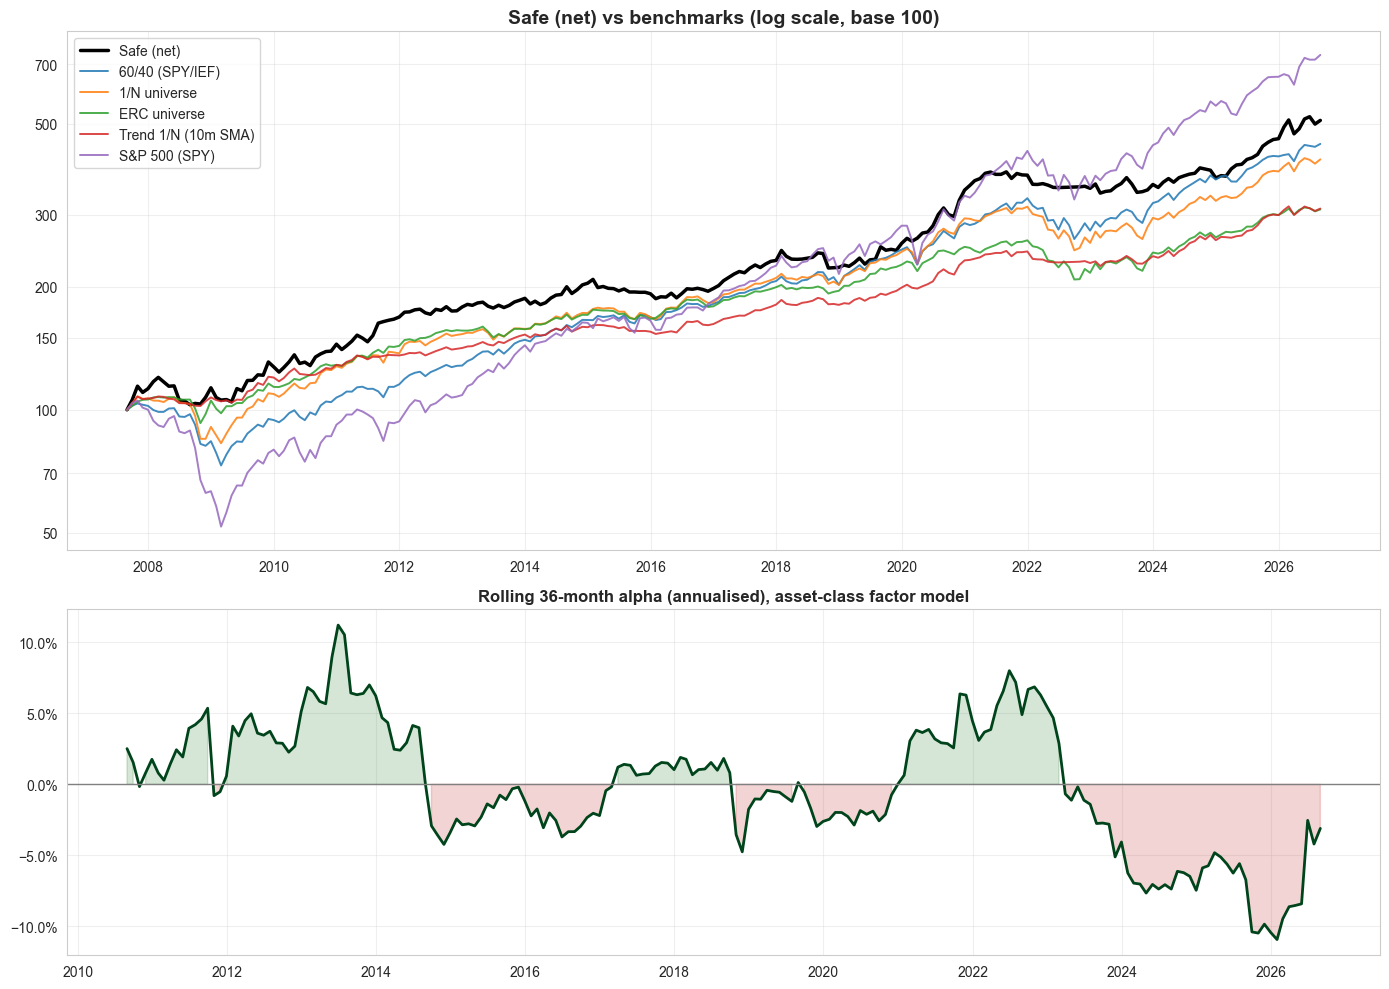

In [9]:
# Model 1: alpha = what static exposure to equities, duration, credit and gold does not explain
# Model 2: + a generic trend-following factor (TSMOM)
asset_class_factors = pd.DataFrame({
    "Equity (SPY-RF)":   R["SPY"] - rf.reindex(R.index),
    "Duration (IEF-RF)": R["IEF"] - rf.reindex(R.index),
    "Credit (LQD-IEF)":  R["LQD"] - R["IEF"],
    "Gold (GLD-RF)":     R["GLD"] - rf.reindex(R.index),
})
tsmom = bm.tsmom_factor(md.prices, md.daily_returns, R, RISKY, rf)
trend_factors = asset_class_factors.assign(**{"Trend (TSMOM)": tsmom})

bm.factor_regression(S, asset_class_factors, RF, "Asset-class factors")
bm.factor_regression(S, trend_factors, RF, "Asset-class factors + trend (TSMOM)")
bm.plot_alpha(S, B, STRAT_NAME, bm.rolling_alpha(S, asset_class_factors, RF), "asset-class factor model")

### Reading the results

Against the 60/40, 1/N and ERC the strategy shows a positive, statistically significant beta-adjusted alpha, with roughly half the drawdown of a 60/40. Against factor models the picture changes: controlling for average exposure to equities, duration, credit and gold leaves an alpha that is no longer significant, and adding a generic trend-following factor shrinks it further. The strategy is best described as a **cheap, implementable trend-following exposure with a diversification filter**, not as a source of independent alpha. Its value is the drawdown profile at 60/40-like returns.